Section 1: Data Loading & Model Setup
This section loads the test dataset and maps the correct image directory paths.
It initializes the pre-trained ResNet-18 model checkpoint on the active device.
It executes predictions, finds all misclassified images, and displays a confusion matrix.

Current working directory: C:\Users\ASUS\OneDrive\Desktop\visualisation
First image: Images_RGB\Images_RGB\seq_1468843518.1616319190.png
Image exists: True
Successfully loaded model and test data!
Total misclassified images found: 90


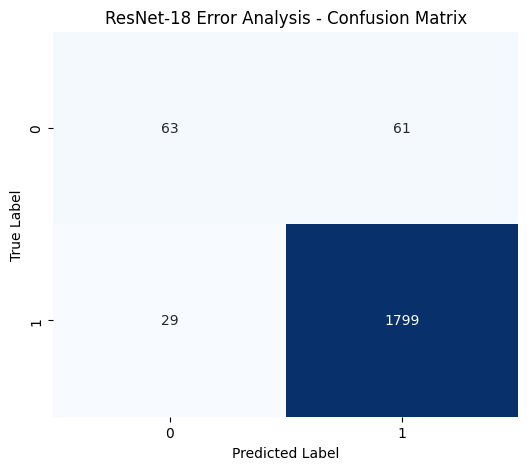


Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.51      0.58       124
           1       0.97      0.98      0.98      1828

    accuracy                           0.95      1952
   macro avg       0.83      0.75      0.78      1952
weighted avg       0.95      0.95      0.95      1952


Indices of misclassified images: [10, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 90, 91, 92, 93, 94, 95, 96, 97, 101, 109, 110, 111, 112, 113, 114, 115, 151, 1219, 1221, 1222, 1323, 1326, 1327, 1366, 1367, 1368, 1386, 1406, 1425, 1426, 1427, 1501, 1511, 1512, 1552, 1553, 1556, 1560, 1561, 1574, 1575, 1589, 1709, 1710]


In [17]:
import os

# 1. Explicitly set working directory to your project root
os.chdir(r"C:\Users\ASUS\OneDrive\Desktop\visualisation")
print("Current working directory:", os.getcwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models
from src import MobilityAidDataset, eval_transform

# 2. Try loading test.csv from root, or fallback to data/test.csv if needed
if os.path.exists("test.csv"):
  test_df = pd.read_csv("test.csv")
elif os.path.exists("data/test.csv"):
  test_df = pd.read_csv("data/test.csv")
else:
  raise FileNotFoundError(
      "Could not find test.csv in project root or data/ folder!"
  )

# Convert to absolute paths so Dataset.py can find the images reliably
test_df["image_path"] = test_df["image_path"].apply(
    lambda x: os.path.abspath(
        os.path.join("Images_RGB", os.path.basename(str(x)))
    )
)

# Verify the fix

test_df["image_path"] = test_df["image_path"].apply(
    lambda x: os.path.join(
        "Images_RGB",
        "Images_RGB",
        os.path.basename(str(x))
    )
)

# Verify image path
print("First image:", test_df["image_path"].iloc[0])
print(
    "Image exists:",
    os.path.isfile(test_df["image_path"].iloc[0])
)

test_dataset = MobilityAidDataset(test_df, transform=eval_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# 3. Set up device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 4. Recreate the ResNet-18 model architecture and load the trained weights
model = models.resnet18(weights=None)
model.fc = nn.Linear(
    model.fc.in_features, 2
)  # Update '2' if your dataset has a different number of classes

checkpoint = torch.load(
    "models/best_resnet18.pth", map_location=device, weights_only=False
)
model.load_state_dict(checkpoint)
model.to(device)
model.eval()

print("Successfully loaded model and test data!")

# 5. Quick loop to run predictions and find errors
all_preds = []
all_labels = []

with torch.no_grad():
 for images, labels in test_loader:
    images = images.to(device)
    outputs = model(images)
    _, preds = torch.max(outputs, 1)

    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Find indices where predictions do not match true labels
error_indices = [
    i for i, (p, t) in enumerate(zip(all_preds, all_labels)) if p != t
]
print(f"Total misclassified images found: {len(error_indices)}")

# 6. Plot and save the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet-18 Error Analysis - Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Print classification metrics and error indices
print("\nClassification Report:")
print(classification_report(all_labels, all_preds))
print(f"\nIndices of misclassified images: {error_indices}")

Section 2: Misclassified Image Visualization
This section extracts indices of images where the model's predictions were incorrect.
It displays up to 12 of these misclassified samples in a clean grid layout.
It helps visually identify potential patterns or common features causing the errors.


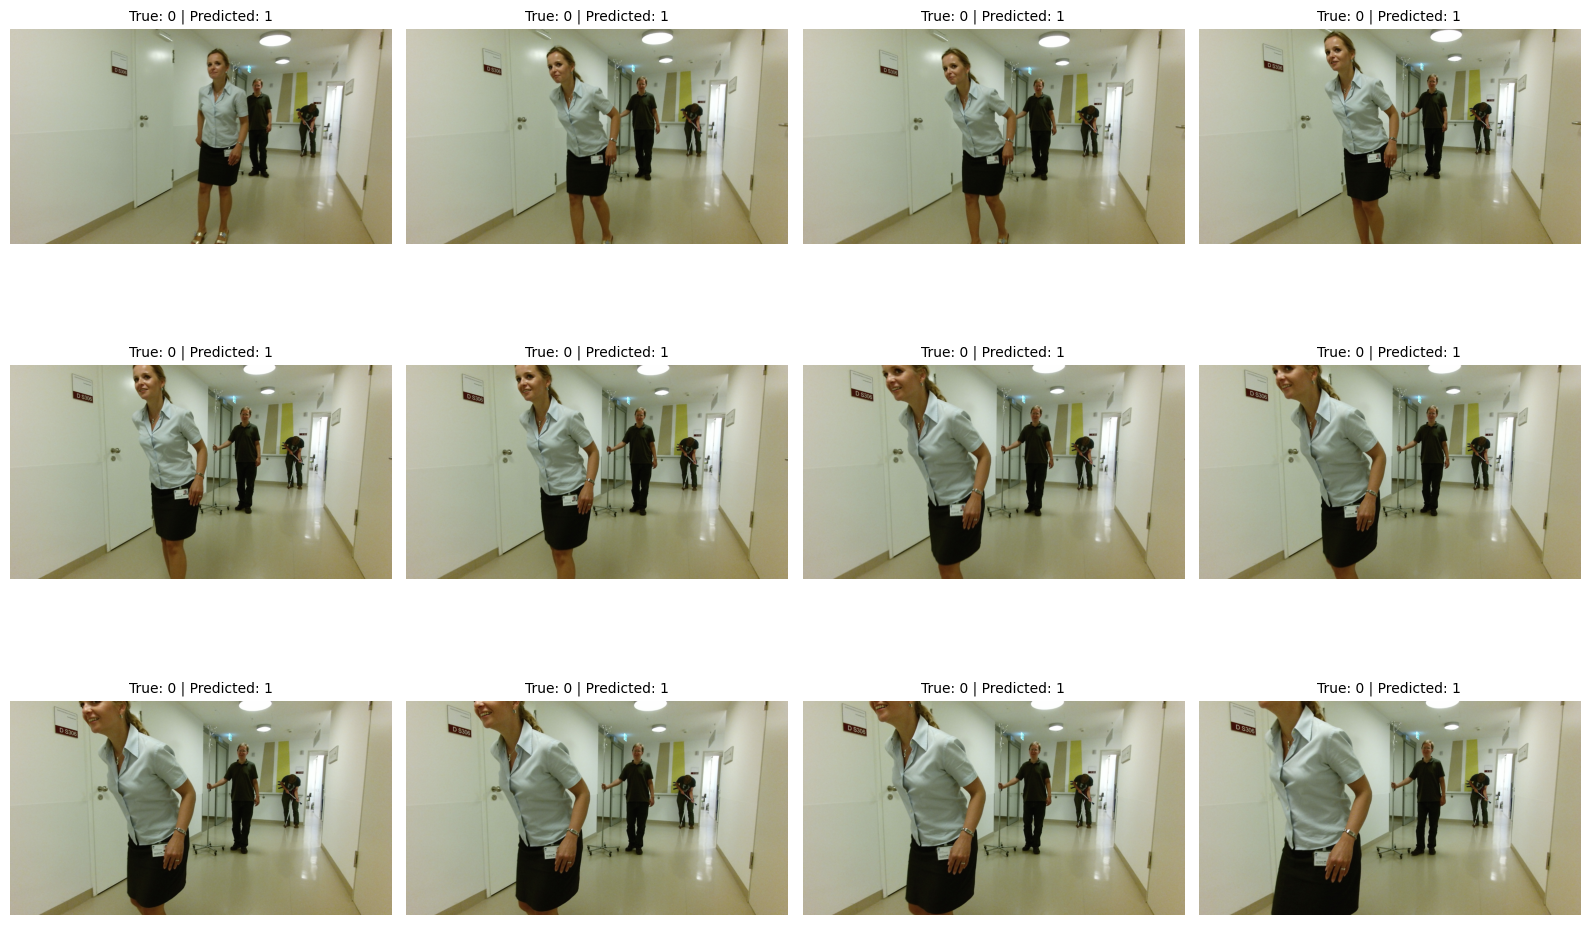

In [20]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Display up to 12 misclassified images
n = min(12, len(error_indices))

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for j in range(n):
    idx = error_indices[j]

    image_path = test_df.iloc[idx]["image_path"]
    true_label = all_labels[idx]
    predicted_label = all_preds[idx]

    img = Image.open(image_path).convert("RGB")

    axes[j].imshow(img)
    axes[j].set_title(
        f"True: {true_label} | Predicted: {predicted_label}",
        fontsize=10
    )
    axes[j].axis("off")

for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=300)
plt.show()

Section 3: Crop Sensitivity Analysis
This section isolates a single misclassified sample and crops out background details.
It runs inference on the cropped frame to evaluate the impact of surrounding clutter.
It reveals whether focusing strictly on the subject corrects the model's prediction.

True Label: 0 | Original Prediction: 1
Cropped Prediction: 0 (Confidence: 0.9990) -> Corrected!


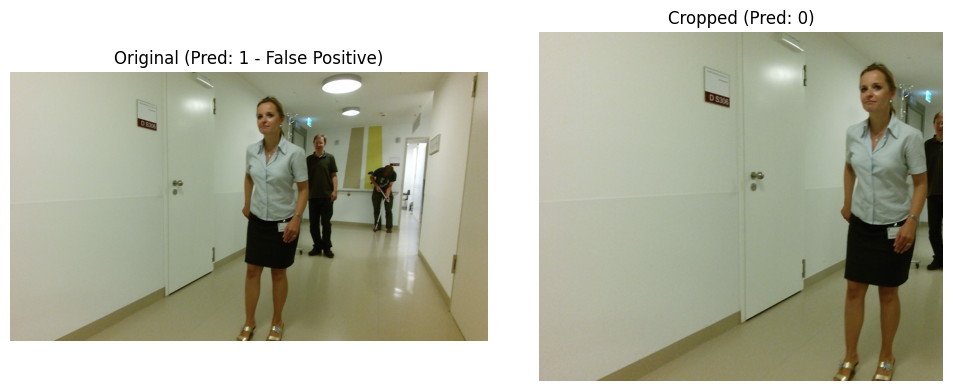

In [21]:
from torchvision.transforms.functional import crop
import torch.nn.functional as F

# Select the first error index from our sequence
idx = error_indices[0]
img_path = test_df.loc[idx, "image_path"]

# Open image
img = Image.open(img_path).convert("RGB")
width, height = img.size

# Define crop coordinates: focus on the foreground person (top, left, right, bottom)
# Adjust these ratios if you want to crop a different section
top = int(height * 0.0)
left = int(width * 0.0)
right = int(width * 0.65)  # Crops out the right side background clutter
bottom = int(height * 1.0)
cropped_img = img.crop((left, top, right, bottom))

# Apply transform and run inference on the cropped image
input_tensor = eval_transform(cropped_img).unsqueeze(0).to(device)
with torch.no_grad():
  output = model(input_tensor)
  prob = F.softmax(output, dim=1)
  pred = torch.argmax(output, dim=1).item()
  conf = prob[0][pred].item()

print(f"True Label: {all_labels[idx]} | Original Prediction: 1")
print(
    f"Cropped Prediction: {pred} (Confidence: {conf:.4f}) ->"
    f" {'Corrected!' if pred == all_labels[idx] else 'Still Incorrect'}"
)

# Display side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img)
axes[0].set_title(f"Original (Pred: 1 - False Positive)")
axes[0].axis("off")

axes[1].imshow(cropped_img)
axes[1].set_title(f"Cropped (Pred: {pred})")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("crop_sensitivity_test.png", dpi=300)
plt.show()

Section 4: Color Inversion Test on Single Image
This section applies an RGB color inversion to a sample to alter its pixel values.
It tests the model's prediction on the inverted version to evaluate feature reliance.
It displays a side-by-side comparison of the original and inverted predictions.

True Label: 0 | Original Prediction: 1
Inverted Prediction: 0 (Confidence: 0.9349) -> Corrected!


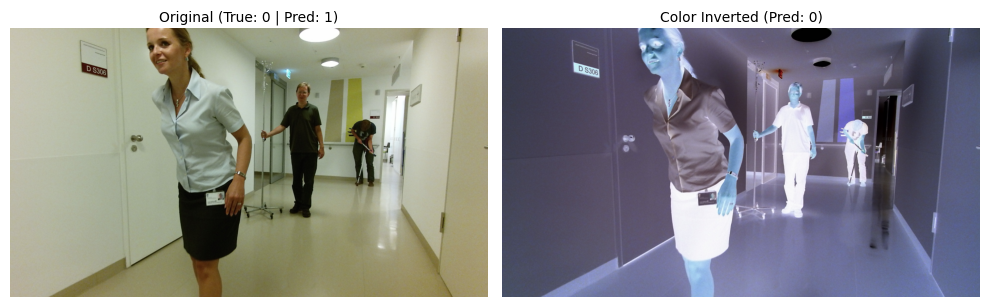

In [22]:
from PIL import Image, ImageOps
import torch.nn.functional as F

# Pick an error index to test
idx = error_indices[5] if len(error_indices) > 5 else error_indices[0]
img_path = test_df.loc[idx, "image_path"]
true_lbl = all_labels[idx]
orig_pred = all_preds[idx]

# Open image and convert to RGB
img = Image.open(img_path).convert("RGB")

# Apply color inversion
inverted_img = ImageOps.invert(img)

# Run inference on the inverted image
input_tensor = eval_transform(inverted_img).unsqueeze(0).to(device)
with torch.no_grad():
  output = model(input_tensor)
  prob = F.softmax(output, dim=1)
  pred = torch.argmax(output, dim=1).item()
  conf = prob[0][pred].item()

print(f"True Label: {true_lbl} | Original Prediction: {orig_pred}")
print(
    f"Inverted Prediction: {pred} (Confidence: {conf:.4f}) ->"
    f" {'Corrected!' if pred == true_lbl else 'Still Incorrect'}"
)

# Display side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img)
axes[0].set_title(
    f"Original (True: {true_lbl} | Pred: {orig_pred})", fontsize=10
)
axes[0].axis("off")

axes[1].imshow(inverted_img)
axes[1].set_title(f"Color Inverted (Pred: {pred})", fontsize=10)
axes[1].axis("off")

plt.tight_layout()
plt.savefig("color_inversion_test.png", dpi=300)
plt.show()

Section 5: Background Occlusion Testing
This section applies a solid black occlusion mask over background clutter in a sample.
It evaluates whether blocking out distracting elements corrects the model's classification.
It demonstrates the model's dependency on background context versus foreground features.

True Label: 0 | Original Prediction: 1
Masked Prediction: 1 (Confidence: 0.9962) -> Still Incorrect


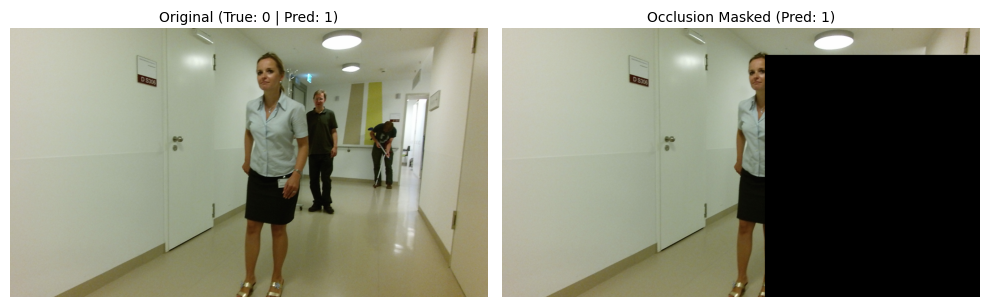

In [25]:
from PIL import Image, ImageDraw
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Select a false positive error index from your results
idx = error_indices[0]
img_path = test_df.loc[idx, "image_path"]
true_lbl = all_labels[idx]
orig_pred = all_preds[idx]

# Open the original image
img = Image.open(img_path).convert("RGB")
w, h = img.size

# 2. Create a copy and draw a black occlusion mask over background clutter
# (Adjust these coordinates [left, top, right, bottom] if your specific background distraction is elsewhere)
masked_img = img.copy()
draw = ImageDraw.Draw(masked_img)
draw.rectangle([int(w * 0.55), int(h * 0.1), w, h], fill="black")

# 3. Run inference on the masked image
input_tensor = eval_transform(masked_img).unsqueeze(0).to(device)
with torch.no_grad():
  output = model(input_tensor)
  prob = F.softmax(output, dim=1)
  pred = torch.argmax(output, dim=1).item()
  conf = prob[0][pred].item()

print(f"True Label: {true_lbl} | Original Prediction: {orig_pred}")
print(
    f"Masked Prediction: {pred} (Confidence: {conf:.4f}) ->"
    f" {'Corrected!' if pred == true_lbl else 'Still Incorrect'}"
)

# 4. Plot and save side-by-side comparison for your slides
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img)
axes[0].set_title(
    f"Original (True: {true_lbl} | Pred: {orig_pred})", fontsize=10
)
axes[0].axis("off")

axes[1].imshow(masked_img)
axes[1].set_title(f"Occlusion Masked (Pred: {pred})", fontsize=10)
axes[1].axis("off")

plt.tight_layout()
plt.savefig("occlusion_sensitivity_test.png", dpi=300)
plt.show()

Section 6: Central Region Masking
This section masks the central region of an image where the main subject is located.
It measures changes in prediction probabilities when the primary subject is obscured.
It shows how much the model depends on peripheral context versus the subject.

True label: 0
Original prediction: 1
Masked prediction: 1
Original probabilities: [[0.27430427 0.7256957 ]]
Masked probabilities: [[0.4001389 0.599861 ]]


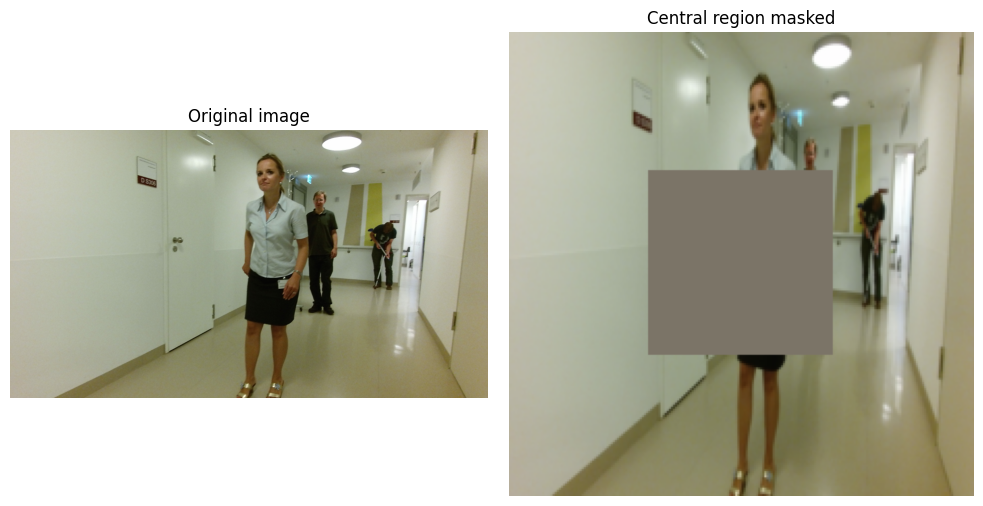

In [26]:

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image

idx = error_indices[0]
img_path = test_df.loc[idx, "image_path"]

img = Image.open(img_path).convert("RGB")

# Resize to model input dimensions
input_img = eval_transform(img)

# Define a black mask
masked_img = input_img.clone()

# Blackout a central region
h, w = masked_img.shape[1], masked_img.shape[2]

top, bottom = int(h * 0.3), int(h * 0.7)
left, right = int(w * 0.3), int(w * 0.7)

masked_img[:, top:bottom, left:right] = 0

# Predict original and masked image
model.eval()

with torch.no_grad():
    original_output = model(input_img.unsqueeze(0).to(device))
    masked_output = model(masked_img.unsqueeze(0).to(device))

    original_prob = F.softmax(original_output, dim=1)
    masked_prob = F.softmax(masked_output, dim=1)

    original_pred = original_output.argmax(1).item()
    masked_pred = masked_output.argmax(1).item()

print("True label:", all_labels[idx])
print("Original prediction:", original_pred)
print("Masked prediction:", masked_pred)
print("Original probabilities:", original_prob.cpu().numpy())
print("Masked probabilities:", masked_prob.cpu().numpy())

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img)
axes[0].set_title("Original image")

# Convert normalized tensor back to display format
display_img = masked_img.cpu().clone()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_img = (display_img * std + mean).clamp(0, 1)

axes[1].imshow(display_img.permute(1, 2, 0))
axes[1].set_title("Central region masked")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("blackout_masking.png", dpi=300)
plt.show()


Section 7: Full Dataset Color Inversion Experiment
This section applies color inversion to every single image across the test dataset.
It evaluates the global impact on accuracy, classification reports, and metrics.
It plots side-by-side confusion matrices to visualize the systematic bias introduced

Starting full dataset colour inversion...
Total test images: 1952
Processed 200/1952 images
Processed 400/1952 images
Processed 600/1952 images
Processed 800/1952 images
Processed 1000/1952 images
Processed 1200/1952 images
Processed 1400/1952 images
Processed 1600/1952 images
Processed 1800/1952 images
Full dataset colour inversion completed!

COLOUR INVERSION RESULTS
   image_index  true_label  original_prediction  inverted_prediction  \
0            0           0                    0                    0   
1            1           0                    0                    0   
2            2           0                    0                    0   
3            3           0                    0                    0   
4            4           0                    0                    0   
5            5           0                    0                    0   
6            6           0                    0                    0   
7            7           0                    0     

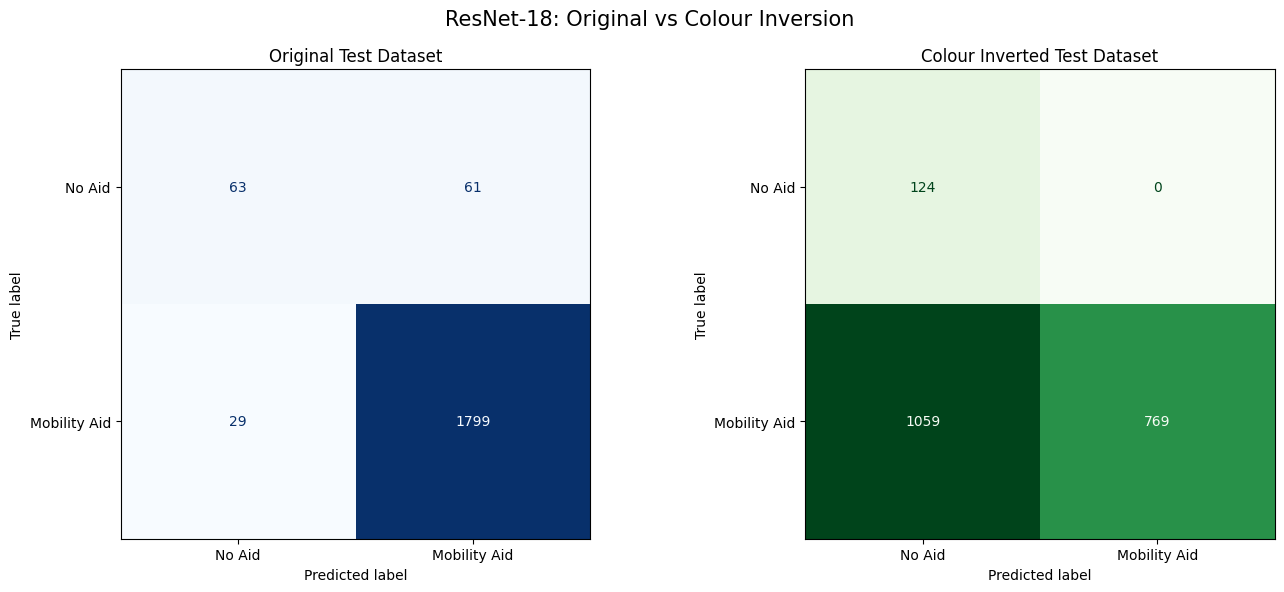


========== PREDICTION CHANGE ANALYSIS ==========
Total images: 1952
Predictions changed: 1091
Predictions unchanged: 861
Correct before inversion: 1862
Correct after inversion: 893
Previously incorrect, now correct: 61
Previously correct, now incorrect: 1030

EXPERIMENT COMPLETED SUCCESSFULLY!
Saved:
- full_dataset_colour_inversion_results.csv
- full_dataset_colour_inversion_summary.csv
- full_dataset_colour_inversion_confusion_matrices.png


In [29]:

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. INITIALIZATION
# ==========================================

model.eval()

results = []

print("Starting full dataset colour inversion...")
print("Total test images:", len(test_df))

# ==========================================
# 2. PROCESS ALL TEST IMAGES
# ==========================================

for idx in range(len(test_df)):

    # Load original image
    img_path = test_df.iloc[idx]["image_path"]
    original_img = Image.open(img_path).convert("RGB")

    # Invert image colours
    inverted_img = ImageOps.invert(original_img)

    # Apply evaluation transformations
    original_tensor = eval_transform(original_img)
    inverted_tensor = eval_transform(inverted_img)

    # Run predictions
    with torch.no_grad():

        original_output = model(
            original_tensor.unsqueeze(0).to(device)
        )

        inverted_output = model(
            inverted_tensor.unsqueeze(0).to(device)
        )

        original_probs = F.softmax(original_output, dim=1)[0]
        inverted_probs = F.softmax(inverted_output, dim=1)[0]

        original_pred = original_probs.argmax().item()
        inverted_pred = inverted_probs.argmax().item()

    true_label = int(all_labels[idx])

    # Store results
    results.append({
        "image_index": idx,
        "true_label": true_label,
        "original_prediction": original_pred,
        "inverted_prediction": inverted_pred,
        "original_confidence": original_probs[original_pred].item(),
        "inverted_confidence": inverted_probs[inverted_pred].item(),
        "prediction_changed": original_pred != inverted_pred,
        "original_correct": original_pred == true_label,
        "inverted_correct": inverted_pred == true_label
    })

    # Show progress
    if (idx + 1) % 200 == 0:
        print(f"Processed {idx + 1}/{len(test_df)} images")

print("Full dataset colour inversion completed!")

# ==========================================
# 3. CREATE RESULTS DATAFRAME
# ==========================================

results_df = pd.DataFrame(results)

print("\nCOLOUR INVERSION RESULTS")
print(results_df.head(10).round(4))

results_df.to_csv(
    "full_dataset_colour_inversion_results.csv",
    index=False
)

# ==========================================
# 4. ACCURACY COMPARISON
# ==========================================

y_true = np.array(all_labels)
y_original = np.array(all_preds)
y_inverted = results_df["inverted_prediction"].to_numpy()

original_accuracy = accuracy_score(y_true, y_original)
inverted_accuracy = accuracy_score(y_true, y_inverted)

print("\n========== ACCURACY COMPARISON ==========")

print(f"Original accuracy: {original_accuracy * 100:.2f}%")
print(f"Inverted accuracy: {inverted_accuracy * 100:.2f}%")

print(
    "Accuracy difference:",
    f"{(inverted_accuracy - original_accuracy) * 100:.2f} percentage points"
)

# ==========================================
# 5. CLASSIFICATION REPORTS
# ==========================================

print("\nORIGINAL CLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_original,
    labels=[0, 1],
    target_names=["No Mobility Aid", "Mobility Aid"],
    zero_division=0
))

print("\nINVERTED CLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_inverted,
    labels=[0, 1],
    target_names=["No Mobility Aid", "Mobility Aid"],
    zero_division=0
))

# ==========================================
# 6. CONFUSION MATRIX COMPARISON
# ==========================================

cm_original = confusion_matrix(
    y_true, y_original, labels=[0, 1]
)

cm_inverted = confusion_matrix(
    y_true, y_inverted, labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_original,
    display_labels=["No Aid", "Mobility Aid"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("Original Test Dataset")

ConfusionMatrixDisplay(
    confusion_matrix=cm_inverted,
    display_labels=["No Aid", "Mobility Aid"]
).plot(
    ax=axes[1],
    cmap="Greens",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("Colour Inverted Test Dataset")

plt.suptitle(
    "ResNet-18: Original vs Colour Inversion",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "full_dataset_colour_inversion_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. PREDICTION CHANGE ANALYSIS
# ==========================================

changed = y_original != y_inverted

original_correct = y_original == y_true
inverted_correct = y_inverted == y_true

corrected_errors = (~original_correct) & inverted_correct
new_errors = original_correct & (~inverted_correct)

print("\n========== PREDICTION CHANGE ANALYSIS ==========")

print("Total images:", len(y_true))
print("Predictions changed:", changed.sum())
print("Predictions unchanged:", (~changed).sum())

print("Correct before inversion:", original_correct.sum())
print("Correct after inversion:", inverted_correct.sum())

print("Previously incorrect, now correct:", corrected_errors.sum())
print("Previously correct, now incorrect:", new_errors.sum())

# ==========================================
# 8. SAVE FINAL SUMMARY
# ==========================================

summary = pd.DataFrame({
    "Metric": [
        "Total test images",
        "Original accuracy",
        "Inverted accuracy",
        "Predictions changed",
        "Predictions unchanged",
        "Correct before inversion",
        "Correct after inversion",
        "Previously incorrect, now correct",
        "Previously correct, now incorrect"
    ],
    "Value": [
        len(y_true),
        original_accuracy,
        inverted_accuracy,
        int(changed.sum()),
        int((~changed).sum()),
        int(original_correct.sum()),
        int(inverted_correct.sum()),
        int(corrected_errors.sum()),
        int(new_errors.sum())
    ]
})

summary.to_csv(
    "full_dataset_colour_inversion_summary.csv",
    index=False
)

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
print("Saved:")
print("- full_dataset_colour_inversion_results.csv")
print("- full_dataset_colour_inversion_summary.csv")
print("- full_dataset_colour_inversion_confusion_matrices.png")
